Download data from https://wwwn.cdc.gov/nchs/nhanes/continuousnhanes/default.aspx?Cycle=2021-2023. We're working with data from August 2021-23. <br>

The https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/DEMO_L.htm description of the **DEMO_L** data file mentions that all participants in the NHANES August 2021-August 2023 sample are included in this dataset. Therefore, this was initially analyses to identify total number of participants.

In [28]:
import shutil, zipfile
from pathlib import Path
import pandas as pd
from google.colab import drive

drive.mount("/content/drive",force_remount=True)

SHARED_DIR = Path("/content/drive/MyDrive/Ryan CTN Algoverse Data Drive")
print(sorted(f.name for f in SHARED_DIR.iterdir()))

Mounted at /content/drive
['DEMO_L.xpt', 'GHB_L.xpt', 'NHANES_2021-2023_all.zip', 'nhanes_summary.csv', 'nhanes_variable_list.csv', 'wdbc.data', 'wdbc.names']


List of all variables available is obtained from https://wwwn.cdc.gov/nchs/nhanes/search/variablelist.aspx?Cycle=2021-2023#print 

In [26]:
!pip install pdfplumber

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 45.4 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.1/7.1 MB 67.1 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.8/3.8 MB 85.2 MB/s  0:00:00
  Attempting uninstall: Pillow━━━━━━━━━━━━━━━━━━ 0/4 [pypdfium2]
    Found existing installation: pillow 11.3.00m 0/4 [pypdfium2]
    Uninstalling pillow-11.3.0:━━━━━━━━━━━━━ 0/4 [pypdfium2]
      Successfully uninstalled pillow-11.3.0━━━━━━━━━━━━━━━━━━━━━━ 1/4 [Pillow]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pdfplumber]4 [pdfminer.six]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.31.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [27]:
import pdfplumber
import pandas as pd

PDF_PATH = SHARED_DIR / "NHANES August 2021-August 2023 Variable List.pdf"
CSV_PATH = SHARED_DIR / "nhanes_variable_list.csv"

COLUMNS = ["variable_name", "variable_description", "data_file_name", "data_file_description",
           "begin_year", "end_year", "component", "use_constraints"]

def find_years(cells):
    """Index of the last 'Begin Year, End Year' pair (2021, 2023), or None."""
    for i in range(len(cells) - 2, -1, -1):
        if cells[i] == "2021" and cells[i + 1] == "2023":
            return i
    return None

rows, merged = [], []
with pdfplumber.open(PDF_PATH) as pdf:
    for page_no, page in enumerate(pdf.pages, start=1):
        for table in page.extract_tables():
            for row in table:
                cells = [" ".join(c.split()) for c in row if c is not None]
                if not cells or cells[0] == "Variable Name":
                    continue
                y = find_years(cells)
                if y is None or y < 3:
                    # Not a full row: text that spilled over from the previous row
                    text = " ".join(c for c in cells if c)
                    if rows and text:
                        rows[-1][1] = f"{rows[-1][1]} {text}".strip()
                    merged.append((page_no, cells))
                    continue
                rows.append([
                    cells[0],                                   # variable_name
                    " ".join(c for c in cells[1:y - 2] if c),   # variable_description (re-joined if split)
                    cells[y - 2],                               # data_file_name
                    cells[y - 1],                               # data_file_description
                    cells[y], cells[y + 1],                     # begin_year, end_year
                    cells[y + 2] if y + 2 < len(cells) else "", # component
                    cells[y + 3] if y + 3 < len(cells) else "", # use_constraints
                ])

vars_df = pd.DataFrame(rows, columns=COLUMNS)
vars_df.to_csv(CSV_PATH, index=False)
print(f"{len(vars_df)} rows saved to {CSV_PATH}")

print("\nFragments merged into the previous row (check these):")
for page_no, cells in merged:
    print(f"  page {page_no}: {cells}")


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/Ryan CTN Algoverse Data Drive/NHANES August 2021-August 2023 Variable List.pdf'

In [29]:
vars_df= pd.read_csv(SHARED_DIR / "nhanes_variable_list.csv")

In [30]:
vars_df.head()

,variable_name,variable_description,data_file_name,data_file_description,begin_year,end_year,component,use_constraints
0,SEQN,Respondent sequence number.,UCPREG_L,Urine Pregnancy Test,2021,2023,Laboratory,NaN
1,URXPREG,Urine Pregnancy Result,UCPREG_L,Urine Pregnancy Test,2021,2023,Laboratory,NaN
2,LBXAGP,alpha-1-acid glycoprotein (g/L),AGP_L,alpha-1-Acid Glycoprotein,2021,2023,Laboratory,NaN
3,SEQN,Respondent sequence number.,AGP_L,alpha-1-Acid Glycoprotein,2021,2023,Laboratory,NaN
4,WTPH2YR,Phlebotomy 2 Year Weight,AGP_L,alpha-1-Acid Glycoprotein,2021,2023,Laboratory,NaN


In [31]:
print(f"Number of unique variables for which data has been collected is {vars_df["variable_name"].nunique()}")

Number of unique variables for which data has been collected is 1313


In [32]:
print(f"Total number of variables is {(vars_df['variable_name'] != 'SEQN').sum()}")


Total number of variables is 1406


In [33]:
print(f"Number of components for which data is collected is:{vars_df["component"].nunique()}")
print(f"Number of unique data values is:{vars_df["data_file_name"].nunique()}")


Number of components for which data is collected is:5
Number of unique data values is:91


In [34]:
restricted = vars_df["data_file_name"].str.upper().str.endswith("_R")

print("Variables in restricted files:", restricted.sum())
print("Number of restricted files:", vars_df.loc[restricted, "data_file_name"].nunique())
print(sorted(vars_df.loc[restricted, "data_file_name"].unique()))


Variables in restricted files: 94
Number of restricted files: 12
['ALQY_L_R', 'CHLA_L_R', 'CHLM_L_R', 'DPQY_L_R', 'DUQ_L_R', 'HSVA_L_R', 'HSV_L_R', 'MGEA_L_R', 'MGEN_L_R', 'RHQ_L_R', 'SXQY_L_R', 'SXQ_L_R']


In [35]:
import io
# ---- 1. Read only loose .xpt files (ignore .zip files) ----
def read_xpt(source):
    data = Path(source).read_bytes()
    for enc in ("utf-8", "cp1252", "latin-1"):    # some files aren't UTF-8
        try:
            return pd.read_sas(io.BytesIO(data), format="xport", encoding=enc)
        except UnicodeDecodeError:
            continue

raw = {}
for f in sorted(SHARED_DIR.rglob("*")):
    if f.suffix.lower() == ".xpt":
        raw[f.stem.upper()] = read_xpt(f)

print(f"Loaded {len(raw)} files:", sorted(raw))


# ---- 2. Store every file as a dataframe (columns keep their variable codes) ----
dfs = {file_name: df.copy() for file_name, df in raw.items()}

Loaded 2 files: ['DEMO_L', 'GHB_L']


#### Demography data

In [36]:
dfs["DEMO_L"].head()

,SEQN,SDDSRVYR,RIDSTATR,RIAGENDR,RIDAGEYR,RIDAGEMN,RIDRETH1,RIDRETH3,RIDEXMON,RIDEXAGM,...,DMDHRGND,DMDHRAGZ,DMDHREDZ,DMDHRMAZ,DMDHSEDZ,WTINT2YR,WTMEC2YR,SDMVSTRA,SDMVPSU,INDFMPIR
0,130378.0,12.0,2.0,1.0,43.0,NaN,5.0,6.0,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,50055.450807,54374.463898,173.0,2.0,5.00
1,130379.0,12.0,2.0,1.0,66.0,NaN,3.0,3.0,2.0,NaN,...,NaN,NaN,NaN,NaN,NaN,29087.450605,34084.721548,173.0,2.0,5.00
2,130380.0,12.0,2.0,2.0,44.0,NaN,2.0,2.0,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,80062.674301,81196.277992,174.0,1.0,1.41
3,130381.0,12.0,2.0,2.0,5.0,NaN,5.0,7.0,1.0,71.0,...,2.0,2.0,2.0,3.0,NaN,38807.268902,55698.607106,182.0,2.0,1.53
4,130382.0,12.0,2.0,1.0,2.0,NaN,3.0,3.0,2.0,34.0,...,2.0,2.0,3.0,1.0,2.0,30607.519774,36434.146346,182.0,2.0,3.60


#### Glycohaemoglobin data

In [37]:
dfs["GHB_L"].head()

,SEQN,WTPH2YR,LBXGH
0,130378.0,56042.129410,5.6
1,130379.0,37435.705647,5.6
2,130380.0,85328.844519,6.2
3,130386.0,44526.214135,5.1
4,130387.0,22746.296353,5.9


In [38]:
ghb = dfs["GHB_L"].drop(columns="SEQN")

print("Number of participants (rows):", len(ghb))

summary = pd.DataFrame({
    "mean": ghb.mean(numeric_only=True),
    "median": ghb.median(numeric_only=True),
    "std": ghb.std(numeric_only=True),
    "non_missing": ghb.count(),
    "missing": ghb.isna().sum(),
    "missing_%": (ghb.isna().mean() * 100).round(1),
})
display(summary.round(2))



Number of participants (rows): 7199


,mean,median,std,non_missing,missing,missing_%
WTPH2YR,38893.26,31031.85,30918.80,7199,0,0.0
LBXGH,5.71,5.50,1.05,6715,484,6.7


### The below is analysis for the entire dataset

In [39]:
def read_xpt(source, name=""):
    data = source.getvalue() if isinstance(source, io.BytesIO) else Path(source).read_bytes()
    for enc in ("utf-8", "cp1252", "latin-1"):
        try:
            return pd.read_sas(io.BytesIO(data), format="xport", encoding=enc)
        except UnicodeDecodeError:
            continue

raw = {}
for f in [SHARED_DIR / "NHANES_2021-2023_all.zip"]:
    with zipfile.ZipFile(f) as z:
        for name in z.namelist():
            if name.lower().endswith(".xpt"):
                raw[Path(name).stem.upper()] = read_xpt(io.BytesIO(z.read(name)), name)
    print(f"Read {f.name}")

print(f"Loaded {len(raw)} files:", sorted(raw))


Read NHANES_2021-2023_all.zip
Loaded 82 files: ['ACQ_L', 'AGP_L', 'ALB_CR_L', 'ALQ_L', 'AUQ_L', 'BAQ_L', 'BAX_L', 'BCHE_L', 'BIOPRO_L', 'BMX_L', 'BPQ_L', 'BPXO_L', 'CBC_L', 'COT_L', 'DBQ_L', 'DEMO_L', 'DEQ_L', 'DIQ_L', 'DPQ_L', 'DR1IFF_L', 'DR1TOT_L', 'DR2IFF_L', 'DR2TOT_L', 'DRXFCD_L', 'DSBI', 'DSII', 'DSPI', 'DSQIDS_L', 'DSQTOT_L', 'ECQ_L', 'FAR_L', 'FASTQX_L', 'FERTIN_L', 'FFMR_L', 'FNQ_L', 'FOLATE_L', 'FOLFMS_L', 'FSQ_L', 'GHB_L', 'GLU_L', 'HDL_L', 'HEPA_L', 'HEPBD_L', 'HEPB_S_L', 'HEPC_L', 'HEPE_L', 'HEQ_L', 'HIQ_L', 'HOQ_L', 'HSCRP_L', 'HSQ_L', 'HUQ_L', 'IHGEM_L', 'IMQ_L', 'INQ_L', 'INS_L', 'KIQ_U_L', 'LUX_L', 'MCQ_L', 'OCQ_L', 'OHQ_L', 'PAQY_L', 'PAQ_L', 'PBCD_L', 'PFAS_L', 'PUQMEC_L', 'RHQ_L', 'RXQASA_L', 'RXQ_RX_L', 'SLQ_L', 'SMQFAM_L', 'SMQRTU_L', 'SMQ_L', 'TCHOL_L', 'TFR_L', 'TRIGLY_L', 'TST_L', 'UCPREG_L', 'VID_L', 'VOCWB_L', 'VTQ_L', 'WHQ_L']


Note: Total number of variables in the `vars_df` is 91, but 12 of them have restricted access (the variable title ends with `_R`), and the Dietary supplement reference databases (DSBI, DSII, DSPI) are not in the dataframe. This is why the number of files in the `.zip` is 82. 

In [40]:
# ---- 2. Store every file as a dataframe (columns keep their variable codes) ----
dfs = {file_name: df.copy() for file_name, df in raw.items()}

In [41]:
dfs["WHQ_L"].head()

,SEQN,WHD010,WHD020,WHD050,WHQ070
0,130378.0,71.0,190.0,200.0,1.0
1,130379.0,70.0,220.0,220.0,2.0
2,130380.0,60.0,150.0,165.0,1.0
3,130384.0,68.0,204.0,212.0,1.0
4,130385.0,70.0,240.0,240.0,2.0


In [42]:
base = "DEMO_L"
nhanes_all = dfs[base].copy()
skipped = {}

for name, df in dfs.items():
    if name == base:
        continue
    if "SEQN" not in df.columns:
        skipped[name] = "no SEQN column"
        continue
    if df["SEQN"].duplicated().any():
        skipped[name] = f"multiple rows per participant ({len(df)} rows, {df['SEQN'].nunique()} people)"
        continue

    # Same variable code in two files always holds the same value, so keep only the first copy
    df = df.drop(columns=[c for c in df.columns if c != "SEQN" and c in nhanes_all.columns])

    nhanes_all = nhanes_all.merge(df, on="SEQN", how="left")   # DEMO_L is the base; missing = NaN

print("Shape:", nhanes_all.shape)
print("Participants:", nhanes_all["SEQN"].nunique())
print("Not merged:", skipped)


Shape: (11933, 1083)
Participants: 11933
Not merged: {'DR1IFF_L': 'multiple rows per participant (100116 rows, 6751 people)', 'DR2IFF_L': 'multiple rows per participant (88032 rows, 5879 people)', 'DRXFCD_L': 'no SEQN column', 'DSBI': 'no SEQN column', 'DSII': 'no SEQN column', 'DSPI': 'no SEQN column', 'DSQIDS_L': 'multiple rows per participant (11375 rows, 4017 people)'}


In [43]:
for name, reason in skipped.items():
    info = vars_df[vars_df["data_file_name"].str.upper() == name]

    print("=" * 80)
    if info.empty:
        print(f"{name}: not found in the variable list")
        print(f"  Reason not merged: {reason}")
        continue

    print(f"{name}: {info['data_file_description'].iloc[0]}")
    print(f"  Component(s): {', '.join(info['component'].unique())}")
    print(f"  Reason not merged: {reason}")
    print(f"  {len(info)} variables:")
    for _, r in info.iterrows():
        print(f"    {r['variable_name']:<10} {r['component']:<14} {r['variable_description']}")

# ---- Components across all skipped files ----
skipped_vars = vars_df[vars_df["data_file_name"].str.upper().isin(skipped)]
print("=" * 80)
print("Components of the not-merged data:")
display(
    skipped_vars.groupby("component")
    .agg(n_files=("data_file_name", "nunique"),
         n_variables=("variable_name", "count"),
         files=("data_file_name", lambda s: ", ".join(sorted(s.unique()))))
)
print("Number of unique components (not-merged data):", skipped_vars["component"].nunique())
print(sorted(skipped_vars["component"].unique()))


DR1IFF_L: Dietary Interview - Individual Foods, First Day
  Component(s): Dietary
  Reason not merged: multiple rows per participant (100116 rows, 6751 people)
  84 variables:
    DR1_020    Dietary        What time did you begin to eat/drink the meal/food?
    DR1_030Z   Dietary        Name of eating occasion
    DR1_040Z   Dietary        Did you eat this meal at home?
    DR1CCMNM   Dietary        Combination food number (sequential number) Variable Data File Begin Use Name Variable Description Name Data File Description Year EndYear Component Constraints DR1CCMTX Combination food type DR1IFF_L Dietary Interview - 2021 2023 Dietary None Individual Foods, First Day DR1DAY Intake day of the week DR1IFF_L Dietary Interview - 2021 2023 Dietary None Individual Foods, First Day DR1DBIH Number of days between intake day and DR1IFF_L Dietary Interview - 2021 2023 Dietary None the day of family questionnaire Individual Foods, First administered in the household. Day DR1DRSTZ Dietary recall st

,n_files,n_variables,files
component,,,
Dietary,4,217,"DR1IFF_L, DR2IFF_L, DRXFCD_L, DSQIDS_L"


Number of unique components (not-merged data): 1
['Dietary']


In [44]:
nhanes_all.shape

(11933, 1083)

In [45]:
cols = nhanes_all.drop(columns="SEQN")
num = cols.select_dtypes("number")

nhanes_summary = pd.DataFrame({
    "mean": num.mean(),
    "median": num.median(),
    "std": num.std(),
    "missing": cols.isna().sum(),
}).reindex(cols.columns)        # keep the original column order

print(nhanes_summary.shape)     # (number of columns - 1, 4)
display(nhanes_summary)


(1082, 4)


,mean,median,std,missing
SDDSRVYR,12.000000,12.0,0.000000,0
RIDSTATR,1.742479,2.0,0.437287,0
RIAGENDR,1.532808,2.0,0.498943,0
RIDAGEYR,38.317858,37.0,25.601990,0
RIDAGEMN,11.628647,11.0,6.805429,11556
...,...,...,...,...
VTD281B,18.300000,19.0,11.915738,11853
WHD010,150.146712,66.0,906.045672,3447
WHD020,317.142588,174.0,1120.476550,3447
WHD050,420.465237,175.0,1491.928102,3447


In [46]:
# File -> component, from the variable list
file_component = (vars_df.assign(file=vars_df["data_file_name"].str.upper())
                  .drop_duplicates("file").set_index("file")["component"])

# Column name in nhanes_all -> source file
col_file = {}
for file_name, df in dfs.items():
    for col in df.columns:
        col_file.setdefault(col, file_name)               # first file a column came from (DEMO_L wins)
        col_file[f"{col} [{file_name}]"] = file_name     # columns tagged with the file name during the merge

cols = nhanes_all.drop(columns="SEQN")
num = cols.select_dtypes("number")

nhanes_summary = pd.DataFrame({
    "component": cols.columns.map(lambda c: file_component.get(col_file.get(c), "Unknown")),
    "mean": num.mean(),
    "median": num.median(),
    "std": num.std(),
    "missing": cols.isna().sum(),
}, index=cols.columns)

print(nhanes_summary.shape)
print(nhanes_summary["component"].value_counts())
display(nhanes_summary)


(1082, 5)
component
Laboratory       364
Questionnaire    319
Dietary          285
Examination       88
Demographics      26
Name: count, dtype: int64


,component,mean,median,std,missing
SDDSRVYR,Demographics,12.000000,12.0,0.000000,0
RIDSTATR,Demographics,1.742479,2.0,0.437287,0
RIAGENDR,Demographics,1.532808,2.0,0.498943,0
RIDAGEYR,Demographics,38.317858,37.0,25.601990,0
RIDAGEMN,Demographics,11.628647,11.0,6.805429,11556
...,...,...,...,...,...
VTD281B,Questionnaire,18.300000,19.0,11.915738,11853
WHD010,Questionnaire,150.146712,66.0,906.045672,3447
WHD020,Questionnaire,317.142588,174.0,1120.476550,3447
WHD050,Questionnaire,420.465237,175.0,1491.928102,3447


In [47]:
# Summary statistics for every variable in nhanes_all, with the component it belongs to
# (file_component / col_file come from the cell above)
cols = nhanes_all.drop(columns="SEQN")
num = cols.select_dtypes("number")

nhanes_summary = pd.DataFrame({
    "component": cols.columns.map(lambda c: file_component.get(col_file.get(c), "Unknown")),
    "mean": num.mean(),
    "median": num.median(),
    "std": num.std(),
    "min": num.min(),
    "max": num.max(),
    "missing": cols.isna().sum(),
}, index=cols.columns)

nhanes_summary.to_csv(SHARED_DIR / "nhanes_summary.csv", index_label="variable")
print(nhanes_summary.shape)
print(nhanes_summary["component"].value_counts())
display(nhanes_summary)


(1082, 7)
component
Laboratory       364
Questionnaire    319
Dietary          285
Examination       88
Demographics      26
Name: count, dtype: int64


,component,mean,median,std,min,max,missing
SDDSRVYR,Demographics,12.000000,12.0,0.000000,1.200000e+01,12.0,0
RIDSTATR,Demographics,1.742479,2.0,0.437287,1.000000e+00,2.0,0
RIAGENDR,Demographics,1.532808,2.0,0.498943,1.000000e+00,2.0,0
RIDAGEYR,Demographics,38.317858,37.0,25.601990,5.397605e-79,80.0,0
RIDAGEMN,Demographics,11.628647,11.0,6.805429,5.397605e-79,24.0,11556
...,...,...,...,...,...,...,...
VTD281B,Questionnaire,18.300000,19.0,11.915738,1.000000e+00,48.0,11853
WHD010,Questionnaire,150.146712,66.0,906.045672,4.000000e+01,9999.0,3447
WHD020,Questionnaire,317.142588,174.0,1120.476550,6.300000e+01,9999.0,3447
WHD050,Questionnaire,420.465237,175.0,1491.928102,6.700000e+01,9999.0,3447


Saved plot to /tmp/nhanes_missing_by_component.png


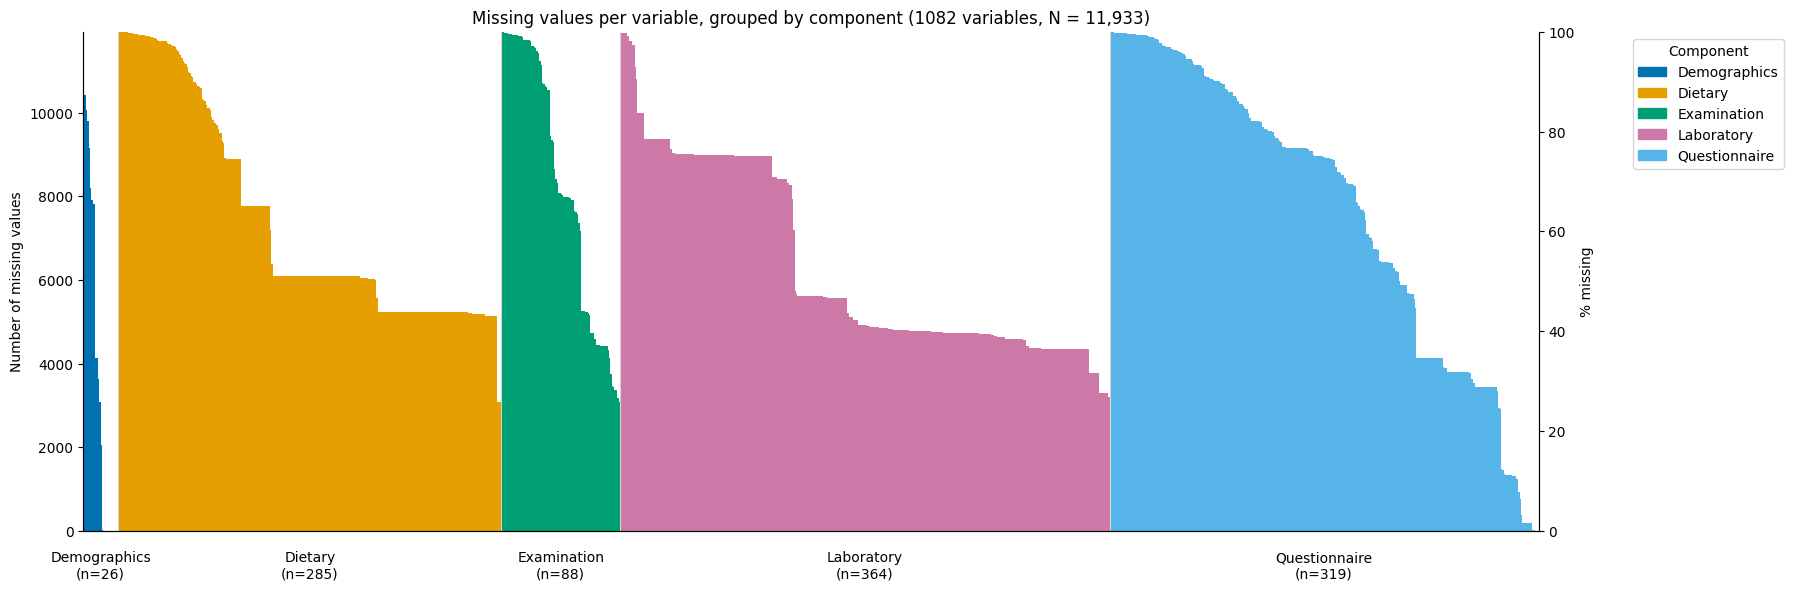

In [50]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

N = len(nhanes_all)  # 11,933 participants

# Colorblind-safe palette, one color per component
palette = {
    "Demographics":  "#0072B2",
    "Dietary":       "#E69F00",
    "Examination":   "#009E73",
    "Laboratory":    "#CC79A7",
    "Questionnaire": "#56B4E9",
    "Unknown":       "#999999",
}

# Group by component, then sort by missing (high -> low) within each component
plot_df = (nhanes_summary.reset_index(names="variable")
           .sort_values(["component", "missing"], ascending=[True, False])
           .reset_index(drop=True))

fig, ax = plt.subplots(figsize=(18, 6))
ax.bar(plot_df.index, plot_df["missing"], width=1.0,
       color=plot_df["component"].map(palette))

# Component labels along the x-axis, plus dividers between groups
for comp, grp in plot_df.groupby("component", sort=False):
    start, end = grp.index.min(), grp.index.max()
    ax.text((start + end) / 2, -0.04, f"{comp}\n(n={len(grp)})",
            transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=10)
    ax.axvline(end + 0.5, color="lightgray", lw=0.8)

ax.set_xlim(-0.5, len(plot_df) - 0.5)
ax.set_xticks([])
ax.set_ylim(0, N)
ax.set_ylabel("Number of missing values")
ax.set_title(f"Missing values per variable, grouped by component ({len(plot_df)} variables, N = {N:,})")

# Second y-axis showing % missing
ax2 = ax.twinx()
ax2.set_ylim(0, 100)
ax2.set_ylabel("% missing")

ax.legend(handles=[Patch(color=palette[c], label=c) for c in plot_df["component"].unique()],
          title="Component", loc="upper left", bbox_to_anchor=(1.06, 1))
for a in (ax, ax2):
    a.spines["top"].set_visible(False)

plt.tight_layout()

# Save to the system temp folder (not Google Drive)
out_path = Path(tempfile.gettempdir()) / "nhanes_missing_by_component.png"
fig.savefig(out_path, dpi=200, bbox_inches="tight")
print(f"Saved plot to {out_path}")

plt.show()


Saved plot to /tmp/nhanes_top40_missing.png


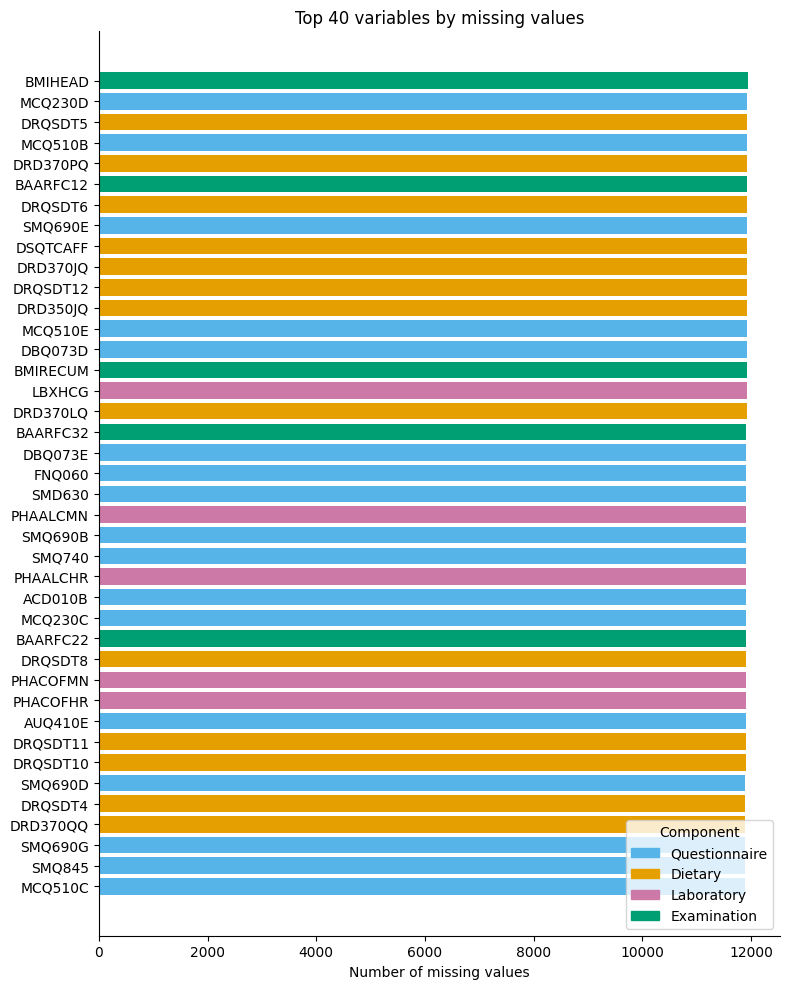

In [51]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib.patches import Patch

# Colorblind-safe palette, one color per component
palette = {
    "Demographics":  "#0072B2",
    "Dietary":       "#E69F00",
    "Examination":   "#009E73",
    "Laboratory":    "#CC79A7",
    "Questionnaire": "#56B4E9",
    "Unknown":       "#999999",
}

# 40 variables with the most missing values (reversed so the largest is on top)
top = nhanes_summary.sort_values("missing", ascending=False).head(40)[::-1]

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(top.index, top["missing"], color=top["component"].map(palette))
ax.set_xlabel("Number of missing values")
ax.set_title("Top 40 variables by missing values")
ax.legend(handles=[Patch(color=palette[c], label=c) for c in top["component"].unique()],
          title="Component", loc="lower right")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)

plt.tight_layout()

# Save to the system temp folder (not Google Drive)
out_path = Path(tempfile.gettempdir()) / "nhanes_top40_missing.png"
fig.savefig(out_path, dpi=200, bbox_inches="tight")
print(f"Saved plot to {out_path}")

plt.show()
